# 🌸 Iris Flower Classification
**Mission 1: Build a Simple Machine Learning Model**

This notebook trains two beginner-friendly models, a **Decision Tree** and **K-Nearest Neighbors (KNN)**, to predict the species of an iris flower, then compares them using accuracy and confusion matrices.

## 1. The Idea

**What does the model predict?**
It predicts the **species** of an iris flower (*setosa*, *versicolor* or *virginica*) from four measurements: sepal length, sepal width, petal length and petal width (all in cm).

**Basic idea:**
In this project, I built a model that guesses which type of iris flower
it is: setosa, versicolor or virginica. It only looks at four
measurements: the **length** and **width** of the **petals**, and the **length** and
**width** of the **sepals**.

**Why I choose this?**
The same approach has **real-world value**. Predicting a category from
measurements is the core idea behind plant-identification apps, medical
screening tools and automated quality control.

## 2. Data Preparation

### 2.1 Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

### 2.2 Load the dataset
The Iris dataset is built into scikit-learn, so no download is needed.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame                      # a table with the 4 features + a 'target' column
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Each row is one flower. The `target` column holds the species as a number: 0 = setosa, 1 = versicolor, 2 = virginica.

In [3]:
# How many flowers of each species?
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
print(df["species"].value_counts())
df = df.drop(columns="species")      # remove helper column again

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### 2.3 Check for missing values
Empty cells can break models, so we always check first.

In [4]:
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Total missing values: 0


✅ There are **no missing values**, so no cleaning is needed.

### 2.4 A quick look at the data

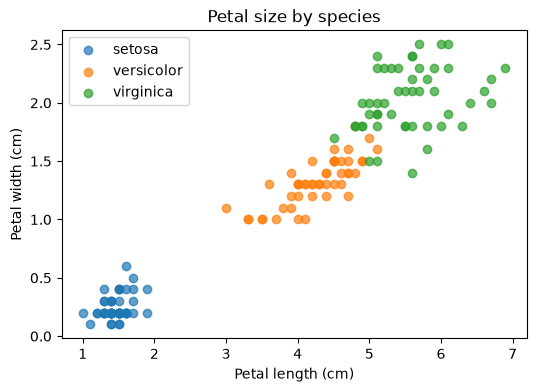

In [5]:
colors = ["tab:blue", "tab:orange", "tab:green"]
plt.figure(figsize=(6, 4))
for i, name in enumerate(iris.target_names):
    subset = df[df["target"] == i]
    plt.scatter(subset["petal length (cm)"], subset["petal width (cm)"],
                label=name, color=colors[i], alpha=0.7)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal size by species")
plt.legend()
plt.show()

Setosa is clearly separated from the others, while versicolor and virginica overlap a little. We'll see this again in the results.

### 2.5 Separate features (X) and target (y)
- **X (features):** the inputs, the 4 measurements
- **y (target):** the answer we want to predict, the species

In [6]:
X = df.drop(columns="target")
y = df["target"]
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (150, 4) | y shape: (150,)


### 2.6 Train/test split
We hide 20% of the flowers from the model. It learns from the other 80% (**training set**) and is then quizzed on the hidden 20% (**test set**), like practising with homework and then taking a real exam.

- `random_state=42` makes the split repeatable.
- `stratify=y` keeps the species balanced in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training flowers:", len(X_train))
print("Test flowers:    ", len(X_test))

Training flowers: 120
Test flowers:     30


## 3. Model Building

**Decision Tree** asks a chain of yes/no questions (e.g. *"Is petal length < 2.5 cm?"*) and follows the answers to a prediction, like a game of 20 Questions.

**K-Nearest Neighbors (KNN)** finds the *K* most similar flowers in the training data (here K = 5) and lets them vote on the species.

`fit()` means "learn from the training data".

In [8]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("Both models trained!")

Both models trained!


## 4. Evaluation

- **Accuracy** = correct predictions ÷ total predictions.
- **Confusion matrix** = a grid showing *which* mistakes were made. Rows are the true species, columns are the predicted species. The diagonal is correct predictions; anything off the diagonal is an error.

Decision Tree accuracy: 93.33%
KNN (k=5) accuracy: 100.00%


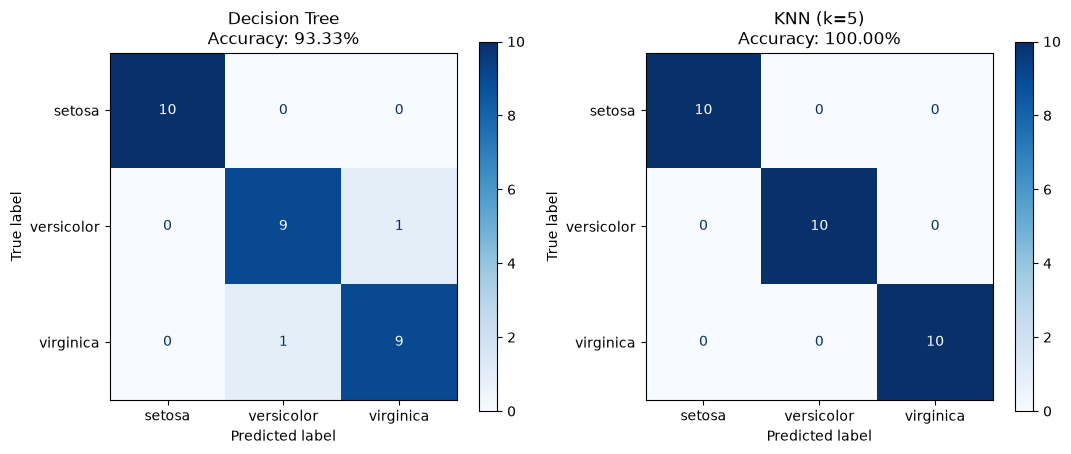

In [9]:
models = {"Decision Tree": tree, "KNN (k=5)": knn}
results = {}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    print(f"{name} accuracy: {acc:.2%}")
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds, display_labels=iris.target_names, ax=ax, cmap="Blues"
    )
    ax.set_title(f"{name}\nAccuracy: {acc:.2%}")
plt.tight_layout()
plt.show()

In [10]:
# Per-species detail for each model
for name, model in models.items():
    print("=" * 55)
    print(name)
    print(classification_report(y_test, model.predict(X_test),
                                target_names=iris.target_names))

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

KNN (k=5)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Bonus: is one test split enough?
With only 30 test flowers, one lucky or unlucky split can change the score a lot. **Cross-validation** repeats the train/test process 5 times on different splits and averages the result, which is a fairer comparison.

In [11]:
from sklearn.model_selection import cross_val_score

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5)
    print(f"{name}: mean accuracy = {scores.mean():.2%}  (± {scores.std():.2%})")

Decision Tree: mean accuracy = 95.33%  (± 3.40%)
KNN (k=5): mean accuracy = 97.33%  (± 2.49%)


## 5. Conclusion

**Which model performed better?**
**KNN (k=5)** performed better. It scored **100%** on the test set (30/30 correct), while the **Decision Tree** scored **93.33%** (28/30 correct). The Decision Tree's two mistakes were between *versicolor* and *virginica*. Cross-validation agrees: KNN averaged about 97.3% vs. about 95.3% for the Decision Tree, so the gap is real but small.

**Validation:** To make sure this was not a lucky split, I confirmed
the result with 5-fold cross-validation. KNN again came out ahead
(97.33% vs 95.33%) and was also more consistent (±2.49% vs ±3.40%).
The advantage is real but modest, since both models performed strongly.


**What I learned**
- Machine learning follows a simple workflow: load data → check for problems → split → train → evaluate.
- We split the data into train and test sets so we can check the model on flowers it has never seen.
- Accuracy is one number; the **confusion matrix** shows *where* a model goes wrong. Setosa is easy, while versicolor and virginica are the species that get confused.
- With a test set of only 30 flowers, one split can be misleading, so cross-validation gives a more trustworthy comparison.
- Simple models can work very well on clean, small datasets.

**Future steps:** I would tune each model and apply the same workflow to a
more complex dataset such as the Mushroom dataset, which requires encoding categorical features.